In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/drsaeedmohsen/ucihar-dataset/UCI-HAR Dataset/README.txt
/kaggle/input/datasets/drsaeedmohsen/ucihar-dataset/UCI-HAR Dataset/activity_labels.txt
/kaggle/input/datasets/drsaeedmohsen/ucihar-dataset/UCI-HAR Dataset/features.txt
/kaggle/input/datasets/drsaeedmohsen/ucihar-dataset/UCI-HAR Dataset/features_info.txt
/kaggle/input/datasets/drsaeedmohsen/ucihar-dataset/UCI-HAR Dataset/test/X_test.txt
/kaggle/input/datasets/drsaeedmohsen/ucihar-dataset/UCI-HAR Dataset/test/subject_test.txt
/kaggle/input/datasets/drsaeedmohsen/ucihar-dataset/UCI-HAR Dataset/test/y_test.txt
/kaggle/input/datasets/drsaeedmohsen/ucihar-dataset/UCI-HAR Dataset/test/Inertial Signals/body_acc_x_test.txt
/kaggle/input/datasets/drsaeedmohsen/ucihar-dataset/UCI-HAR Dataset/test/Inertial Signals/body_acc_y_test.txt
/kaggle/input/datasets/drsaeedmohsen/ucihar-dataset/UCI-HAR Dataset/test/Inertial Signals/body_acc_z_test.txt
/kaggle/input/datasets/drsaeedmohsen/ucihar-dataset/UCI-HAR Dataset/test/Inert

In [2]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("drsaeedmohsen/ucihar-dataset")

print("Path to dataset files:", path)

Path to dataset files: /kaggle/input/datasets/drsaeedmohsen/ucihar-dataset


In [3]:
import os
import numpy as np
import pandas as pd

# auto-detect dataset root
base = None
for root, dirs, files in os.walk("/kaggle/input"):
    if "features.txt" in files:
        base = root + "/"
        break
print("Using:", base)

features = pd.read_csv(base + "features.txt", sep=r"\s+", header=None, names=["idx", "name"])
X_train = pd.read_csv(base + "train/X_train.txt", sep=r"\s+", header=None)
X_test  = pd.read_csv(base + "test/X_test.txt",  sep=r"\s+", header=None)
y_train = pd.read_csv(base + "train/y_train.txt", header=None)[0]
y_test  = pd.read_csv(base + "test/y_test.txt",  header=None)[0]

labels = pd.read_csv(base + "activity_labels.txt", sep=r"\s+", header=None, index_col=0)[1]

print("Train:", X_train.shape, "Test:", X_test.shape)
print("Missing values:", X_train.isna().sum().sum())
print("\nClass distribution (train):")
print(y_train.map(labels).value_counts(normalize=True).round(3))

acc_x = np.loadtxt(base + "train/Inertial Signals/total_acc_x_train.txt")
print("\nRaw windows:", acc_x.shape)  # expect (7352, 128)

Using: /kaggle/input/datasets/drsaeedmohsen/ucihar-dataset/UCI-HAR Dataset/
Train: (7352, 561) Test: (2947, 561)
Missing values: 0

Class distribution (train):
0
LAYING                0.191
STANDING              0.187
SITTING               0.175
WALKING               0.167
WALKING_UPSTAIRS      0.146
WALKING_DOWNSTAIRS    0.134
Name: proportion, dtype: float64

Raw windows: (7352, 128)


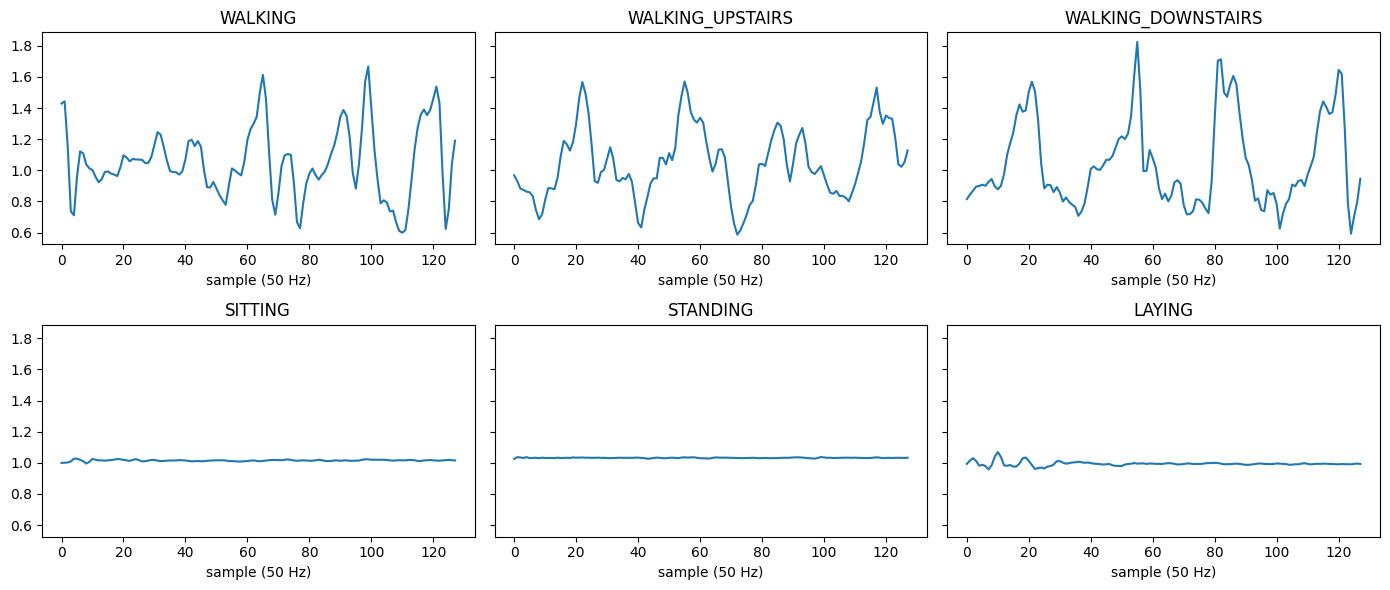

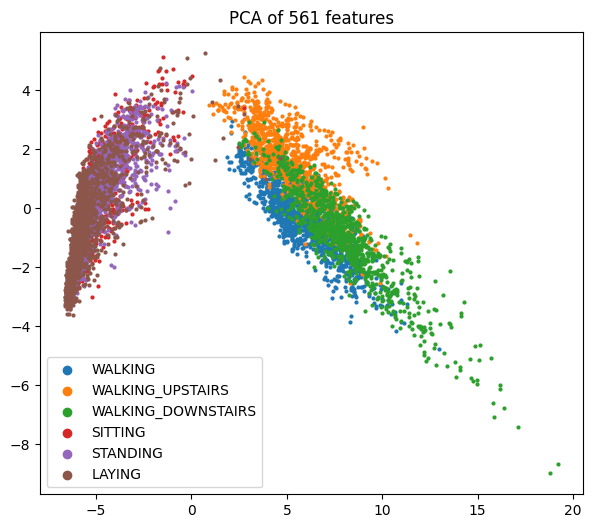

In [4]:
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

sig = base + "train/Inertial Signals/"
ax_ = np.loadtxt(sig + "total_acc_x_train.txt")
ay_ = np.loadtxt(sig + "total_acc_y_train.txt")
az_ = np.loadtxt(sig + "total_acc_z_train.txt")
mag = np.sqrt(ax_**2 + ay_**2 + az_**2)

# 1. one raw acceleration-magnitude window per activity
fig, axes = plt.subplots(2, 3, figsize=(14, 6), sharey=True)
for a, (code, name) in zip(axes.ravel(), labels.items()):
    i = np.where(y_train.values == code)[0][0]
    a.plot(mag[i]); a.set_title(name); a.set_xlabel("sample (50 Hz)")
plt.tight_layout(); plt.show()

# 2. 2-D PCA of the 561 features
p = PCA(n_components=2).fit_transform(X_train)
plt.figure(figsize=(7, 6))
for code, name in labels.items():
    m = y_train.values == code
    plt.scatter(p[m, 0], p[m, 1], s=4, label=name)
plt.legend(markerscale=3); plt.title("PCA of 561 features"); plt.show()

In [5]:
subj_train = pd.read_csv(base + "train/subject_train.txt", header=None)[0]
print(subj_train.nunique(), "subjects in train")  # expect 21

21 subjects in train


LogReg: acc=0.9542, macro-F1=0.9541
RandomForest: acc=0.9257, macro-F1=0.9238
                    precision    recall  f1-score   support

           WALKING       0.94      0.99      0.97       496
  WALKING_UPSTAIRS       0.96      0.95      0.95       471
WALKING_DOWNSTAIRS       0.99      0.94      0.96       420
           SITTING       0.97      0.88      0.92       491
          STANDING       0.89      0.97      0.93       532
            LAYING       1.00      0.99      0.99       537

          accuracy                           0.95      2947
         macro avg       0.96      0.95      0.95      2947
      weighted avg       0.96      0.95      0.95      2947



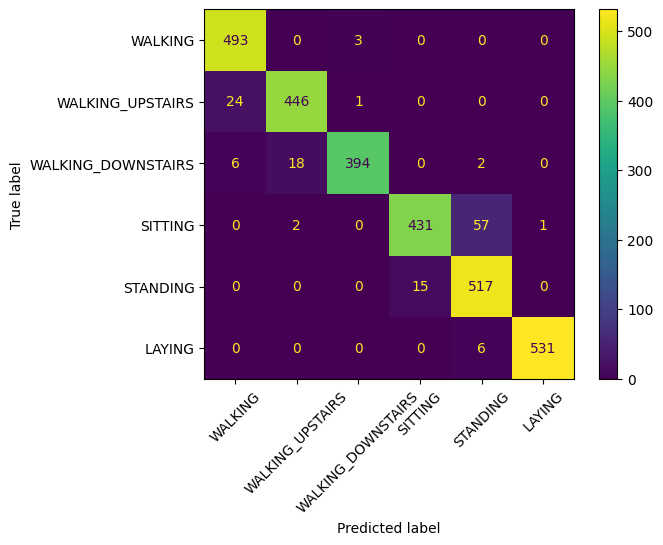

In [6]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

models = {
    "LogReg": make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)),
    "RandomForest": RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1),
}

for name, m in models.items():
    m.fit(X_train, y_train)
    pred = m.predict(X_test)
    print(f"{name}: acc={accuracy_score(y_test, pred):.4f}, macro-F1={f1_score(y_test, pred, average='macro'):.4f}")

# detailed view for LogReg
pred = models["LogReg"].predict(X_test)
print(classification_report(y_test, pred, target_names=labels.values))
ConfusionMatrixDisplay(confusion_matrix(y_test, pred), display_labels=labels.values).plot(xticks_rotation=45)
plt.show()

In [7]:
from scipy.fft import rfft, rfftfreq

fs = 50
freqs = rfftfreq(128, d=1/fs)

def load_signals(split):
    names = ["total_acc_x", "total_acc_y", "total_acc_z",
             "body_gyro_x", "body_gyro_y", "body_gyro_z"]
    return np.stack([np.loadtxt(f"{base}{split}/Inertial Signals/{n}_{split}.txt")
                     for n in names], axis=1)  # (N, 6, 128)

def extract(sig):
    N, C, T = sig.shape
    mag = np.sqrt((sig[:, :3] ** 2).sum(axis=1))[:, None, :]   # (N, 1, 128)
    allsig = np.concatenate([sig, mag], axis=1)                # (N, 7, 128)

    feats, names = [], []
    ch_names = ["accx", "accy", "accz", "gyrx", "gyry", "gyrz", "accmag"]
    for c, ch in enumerate(ch_names):
        s = allsig[:, c, :]
        sc = s - s.mean(axis=1, keepdims=True)                 # remove DC before FFT
        P = np.abs(rfft(sc, axis=1)) ** 2
        Pn = P / (P.sum(axis=1, keepdims=True) + 1e-12)
        f = {
            "mean": s.mean(axis=1),
            "std": s.std(axis=1),
            "min": s.min(axis=1),
            "max": s.max(axis=1),
            "energy": (s ** 2).mean(axis=1),
            "domfreq": freqs[P[:, 1:].argmax(axis=1) + 1],     # skip DC bin
            "specenergy": P.sum(axis=1) / T,
            "specentropy": -(Pn * np.log(Pn + 1e-12)).sum(axis=1),
        }
        for k, v in f.items():
            feats.append(v); names.append(f"{ch}_{k}")
    return np.column_stack(feats), names

S_train, S_test = load_signals("train"), load_signals("test")
F_train, fnames = extract(S_train)
F_test, _ = extract(S_test)
print(F_train.shape, F_test.shape)   # expect (7352, 56) (2947, 56)

# same two models as the baseline
for name, m in models.items():
    m.fit(F_train, y_train)
    pred = m.predict(F_test)
    print(f"{name} (own 56 features): acc={accuracy_score(y_test, pred):.4f}, "
          f"macro-F1={f1_score(y_test, pred, average='macro'):.4f}")

(7352, 56) (2947, 56)
LogReg (own 56 features): acc=0.9023, macro-F1=0.9004
RandomForest (own 56 features): acc=0.9067, macro-F1=0.9045


RF own-56: acc=0.9067, macro-F1=0.9045
                    precision    recall  f1-score   support

           WALKING       0.90      0.93      0.92       496
  WALKING_UPSTAIRS       0.88      0.93      0.90       471
WALKING_DOWNSTAIRS       0.94      0.83      0.88       420
           SITTING       0.89      0.81      0.85       491
          STANDING       0.84      0.91      0.88       532
            LAYING       1.00      1.00      1.00       537

          accuracy                           0.91      2947
         macro avg       0.91      0.90      0.90      2947
      weighted avg       0.91      0.91      0.91      2947



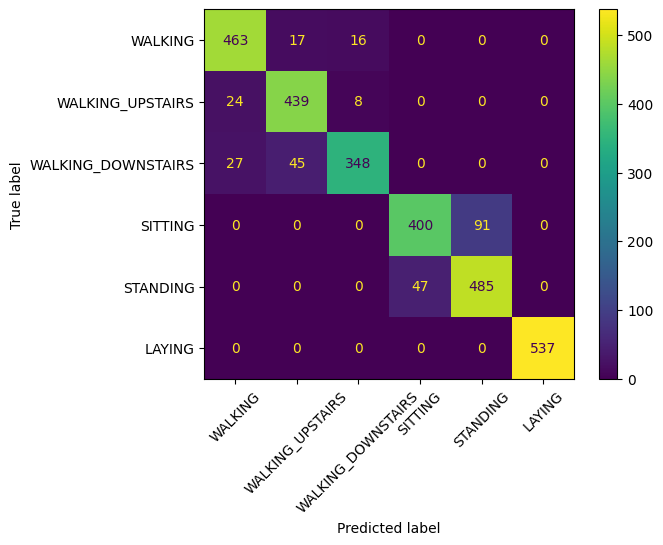

RF time-only (35): acc=0.8259, macro-F1=0.8227
RF freq-only (21): acc=0.8734, macro-F1=0.8727
LogReg 561+56: acc=0.9566, macro-F1=0.9560
RF 561+56: acc=0.9135, macro-F1=0.9123


array([5, 5, 5, ..., 2, 2, 1])

In [8]:
from sklearn.base import clone

rf = RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1)
lr = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000))

def run(tag, model, Xtr, Xte):
    p = clone(model).fit(Xtr, y_train).predict(Xte)
    print(f"{tag}: acc={accuracy_score(y_test, p):.4f}, macro-F1={f1_score(y_test, p, average='macro'):.4f}")
    return p

# 1. where do own features fail?
p_own = run("RF own-56", rf, F_train, F_test)
print(classification_report(y_test, p_own, target_names=labels.values))
ConfusionMatrixDisplay(confusion_matrix(y_test, p_own), display_labels=labels.values).plot(xticks_rotation=45)
plt.show()

# 2. ablation: time-domain vs frequency-domain features
time_k = ("mean", "std", "min", "max", "energy")
t_idx = [i for i, n in enumerate(fnames) if n.split("_")[1] in time_k]
f_idx = [i for i, n in enumerate(fnames) if n.split("_")[1] not in time_k]
for tag, idx in [("time-only (35)", t_idx), ("freq-only (21)", f_idx)]:
    run(f"RF {tag}", rf, F_train[:, idx], F_test[:, idx])

# 3. complementary? provided 561 + own 56
Xc_train = np.hstack([X_train.values, F_train])
Xc_test  = np.hstack([X_test.values,  F_test])
run("LogReg 561+56", lr, Xc_train, Xc_test)
run("RF 561+56", rf, Xc_train, Xc_test)

In [9]:
from sklearn.model_selection import GroupKFold, cross_val_score, GridSearchCV

gkf = GroupKFold(n_splits=5)
groups = subj_train.values

configs = {
    "LogReg 561":     (lr, X_train.values),
    "LogReg 561+56":  (lr, Xc_train),
    "LogReg own-56":  (lr, F_train),
    "RF 561":         (rf, X_train.values),
    "RF own-56":      (rf, F_train),
}
for tag, (m, X) in configs.items():
    s = cross_val_score(m, X, y_train, groups=groups, cv=gkf, scoring="f1_macro")
    print(f"{tag}: macro-F1 = {s.mean():.4f} ± {s.std():.4f}")

# tune LogReg regularization on the 561 features
grid = GridSearchCV(lr, {"logisticregression__C": [0.01, 0.1, 1, 10]},
                    cv=gkf, scoring="f1_macro", n_jobs=-1)
grid.fit(X_train.values, y_train, groups=groups)
print("best:", grid.best_params_, f"CV macro-F1 = {grid.best_score_:.4f}")

LogReg 561: macro-F1 = 0.9331 ± 0.0425
LogReg 561+56: macro-F1 = 0.9322 ± 0.0423
LogReg own-56: macro-F1 = 0.8945 ± 0.0515
RF 561: macro-F1 = 0.9177 ± 0.0448
RF own-56: macro-F1 = 0.9029 ± 0.0484
best: {'logisticregression__C': 0.1} CV macro-F1 = 0.9339


FINAL LogReg C=0.1: acc=0.9498, macro-F1=0.9500
                    precision    recall  f1-score   support

           WALKING       0.94      0.99      0.97       496
  WALKING_UPSTAIRS       0.95      0.95      0.95       471
WALKING_DOWNSTAIRS       0.99      0.94      0.96       420
           SITTING       0.96      0.88      0.91       491
          STANDING       0.88      0.96      0.92       532
            LAYING       1.00      0.97      0.99       537

          accuracy                           0.95      2947
         macro avg       0.95      0.95      0.95      2947
      weighted avg       0.95      0.95      0.95      2947



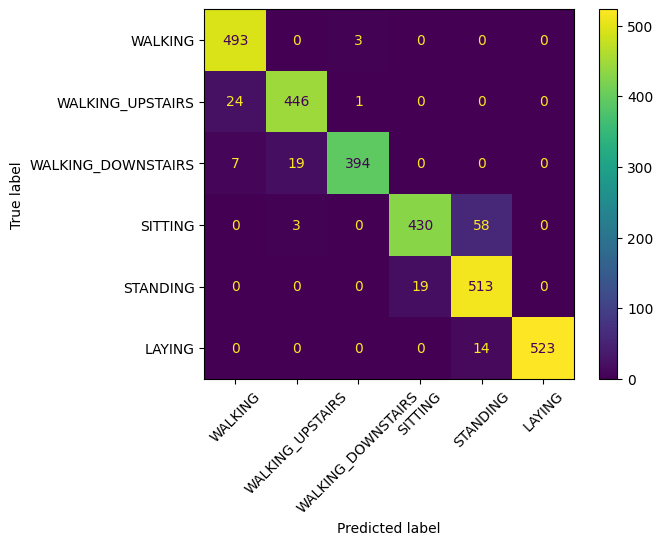

accx_max             0.070
accx_mean            0.065
accmag_std           0.055
accx_energy          0.052
accmag_specenergy    0.052
accmag_max           0.051
accy_mean            0.047
accx_min             0.043
accy_max             0.038
accx_specenergy      0.035
dtype: float64


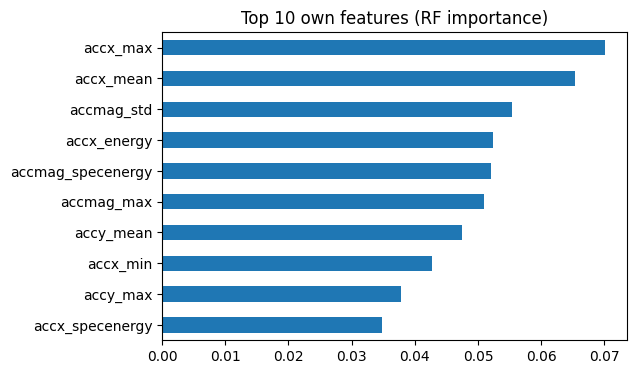

In [10]:
final = make_pipeline(StandardScaler(), LogisticRegression(C=0.1, max_iter=2000))
final.fit(X_train, y_train)
pred = final.predict(X_test)

print(f"FINAL LogReg C=0.1: acc={accuracy_score(y_test, pred):.4f}, macro-F1={f1_score(y_test, pred, average='macro'):.4f}")
print(classification_report(y_test, pred, target_names=labels.values))
ConfusionMatrixDisplay(confusion_matrix(y_test, pred), display_labels=labels.values).plot(xticks_rotation=45)
plt.savefig("final_confusion.png", dpi=150, bbox_inches="tight"); plt.show()

# which of your own features matter most (RF on own-56)
rf_own = RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1).fit(F_train, y_train)
imp = pd.Series(rf_own.feature_importances_, index=fnames).sort_values(ascending=False)
print(imp.head(10).round(3))
imp.head(10)[::-1].plot.barh(figsize=(6, 4), title="Top 10 own features (RF importance)")
plt.savefig("own_feature_importance.png", dpi=150, bbox_inches="tight"); plt.show()